<a href="https://colab.research.google.com/github/clobos/Alimentos_2026/blob/main/Teste_hipoteses_Alimentos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 1

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Configurações gerais para as curvas
mu0, mu1 = 0, 2.8
sigma = 1
x = np.linspace(-4, 6, 1000)
y0 = norm.pdf(x, mu0, sigma)
y1 = norm.pdf(x, mu1, sigma)
alpha = 0.05
x_crit = norm.ppf(1 - alpha, mu0, sigma)
x_crit


np.float64(1.6448536269514722)

## DISTRIBUIÇÃO DA ESTATÍSTICA SOB H0 E SOB H1

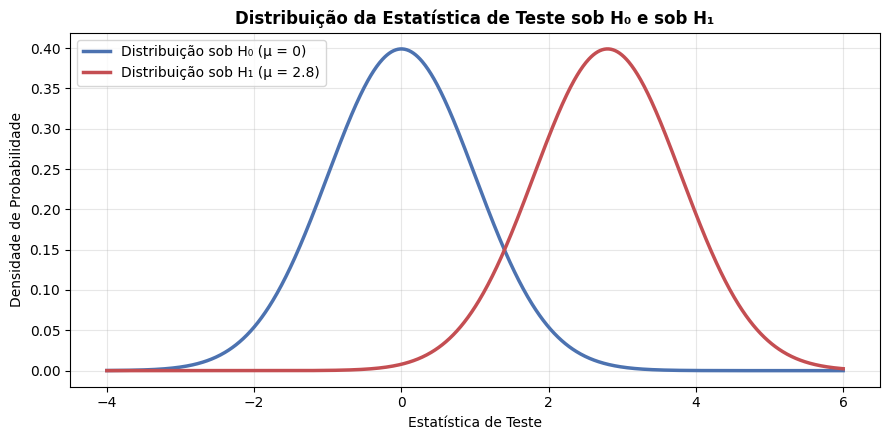

In [ ]:
fig1, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.plot(x, y0, color="#4C72B0", lw=2.5, label="Distribuição sob H₀ (μ = 0)")
ax1.plot(x, y1, color="#C44E52", lw=2.5, label="Distribuição sob H₁ (μ = 2.8)")
ax1.set_title("Distribuição da Estatística de Teste sob H₀ e sob H₁", fontsize=12, fontweight='bold')
ax1.set_xlabel("Estatística de Teste")
ax1.set_ylabel("Densidade de Probabilidade")
ax1.legend()
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

##  NÍVEL DE SIGNIFICÂNCIA ($\alpha$)

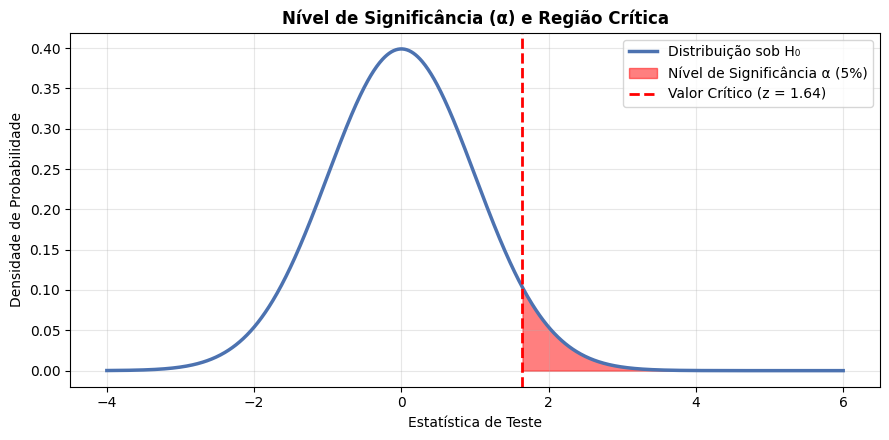

In [ ]:
fig2, ax2 = plt.subplots(figsize=(9, 4.5))
ax2.plot(x, y0, color="#4C72B0", lw=2.5, label="Distribuição sob H₀")
# Preencher a região crítica (Alpha)
x_alpha = np.linspace(x_crit, 6, 500)
y_alpha = norm.pdf(x_alpha, mu0, sigma)
ax2.fill_between(x_alpha, y_alpha, color="red", alpha=0.5, label=f"Nível de Significância α ({alpha*100:.0f}%)")
ax2.axvline(x_crit, color="red", ls="--", lw=2, label=f"Valor Crítico (z = {x_crit:.2f})")
ax2.set_title("Nível de Significância (α) e Região Crítica", fontsize=12, fontweight='bold')
ax2.set_xlabel("Estatística de Teste")
ax2.set_ylabel("Densidade de Probabilidade")
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



## ERRO TIPO I e ERRO TIPO II

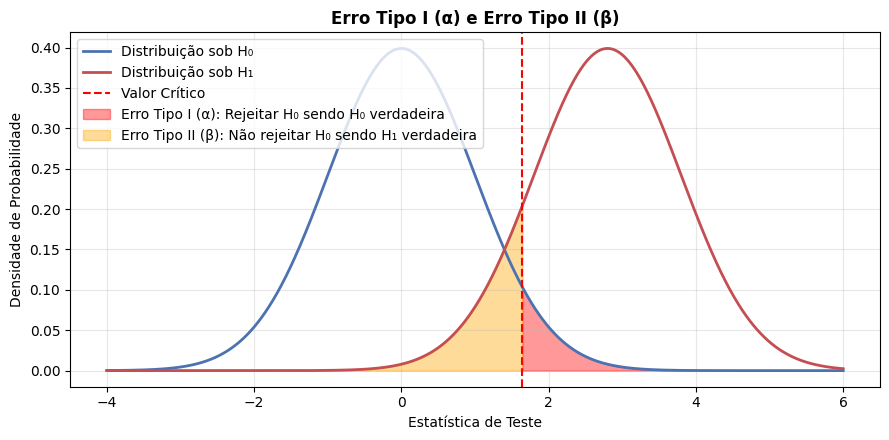

In [ ]:
fig3, ax3 = plt.subplots(figsize=(9, 4.5))
ax3.plot(x, y0, color="#4C72B0", lw=2, label="Distribuição sob H₀")
ax3.plot(x, y1, color="#C44E52", lw=2, label="Distribuição sob H₁")
ax3.axvline(x_crit, color="red", ls="--", lw=1.5, label="Valor Crítico")

# Erro Tipo I (área vermelha sob H0 à direita do valor crítico)
x_err1 = np.linspace(x_crit, 6, 500)
y_err1 = norm.pdf(x_err1, mu0, sigma)
ax3.fill_between(x_err1, y_err1, color="red", alpha=0.4, label="Erro Tipo I (α): Rejeitar H₀ sendo H₀ verdadeira")

# Erro Tipo II (área amarela sob H1 à esquerda do valor crítico)
x_err2 = np.linspace(-4, x_crit, 500)
y_err2 = norm.pdf(x_err2, mu1, sigma)
ax3.fill_between(x_err2, y_err2, color="orange", alpha=0.4, label="Erro Tipo II (β): Não rejeitar H₀ sendo H₁ verdadeira")

ax3.set_title("Erro Tipo I (α) e Erro Tipo II (β)", fontsize=12, fontweight='bold')
ax3.set_xlabel("Estatística de Teste")
ax3.set_ylabel("Densidade de Probabilidade")
ax3.legend(loc="upper left")
ax3.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



## PODER DO TESTE (1 - $\beta$)

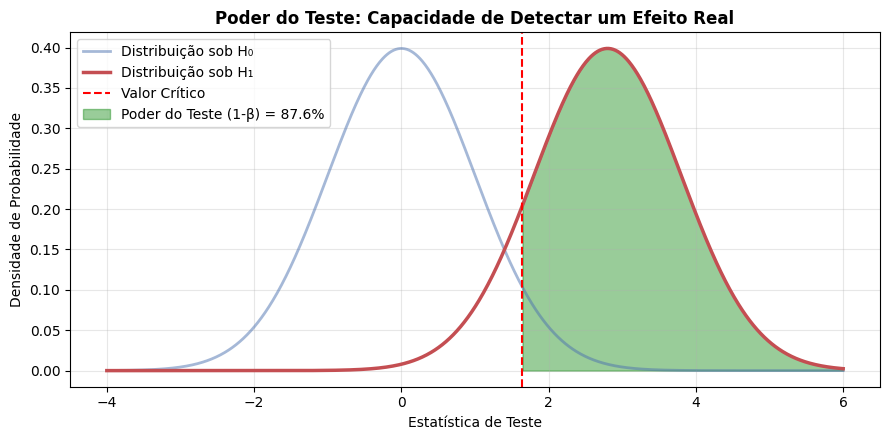

In [ ]:
fig4, ax4 = plt.subplots(figsize=(9, 4.5))
ax4.plot(x, y0, color="#4C72B0", lw=2, alpha=0.5, label="Distribuição sob H₀")
ax4.plot(x, y1, color="#C44E52", lw=2.5, label="Distribuição sob H₁")
ax4.axvline(x_crit, color="red", ls="--", lw=1.5, label="Valor Crítico")

# Poder do teste (área verde sob H1 à direita do valor crítico)
x_power = np.linspace(x_crit, 6, 500)
y_power = norm.pdf(x_power, mu1, sigma)
power_val = 1 - norm.cdf(x_crit, mu1, sigma)
ax4.fill_between(x_power, y_power, color="green", alpha=0.4, label=f"Poder do Teste (1-β) = {power_val*100:.1f}%")

ax4.set_title("Poder do Teste: Capacidade de Detectar um Efeito Real", fontsize=12, fontweight='bold')
ax4.set_xlabel("Estatística de Teste")
ax4.set_ylabel("Densidade de Probabilidade")
ax4.legend(loc="upper left")
ax4.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



## CONCEITO DE P-VALOR

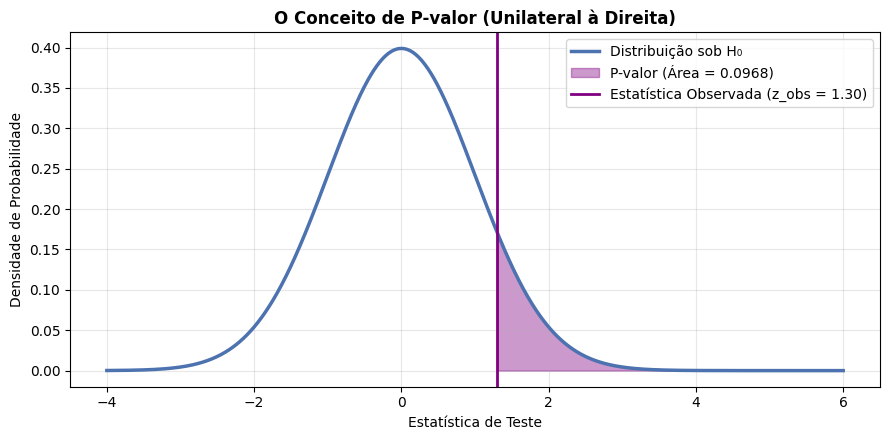

In [ ]:
fig5, ax5 = plt.subplots(figsize=(9, 4.5))
ax5.plot(x, y0, color="#4C72B0", lw=2.5, label="Distribuição sob H₀")

# Simular uma estatística observada
z_obs = 1.3
y_obs = norm.pdf(z_obs, mu0, sigma)
p_value = 1 - norm.cdf(z_obs, mu0, sigma)

# Área do p-valor (à direita do valor observado)
x_p = np.linspace(z_obs, 6, 500)
y_p = norm.pdf(x_p, mu0, sigma)
ax5.fill_between(x_p, y_p, color="purple", alpha=0.4, label=f"P-valor (Área = {p_value:.4f})")
ax5.axvline(z_obs, color="purple", ls="-", lw=2, label=f"Estatística Observada (z_obs = {z_obs:.2f})")

ax5.set_title("O Conceito de P-valor (Unilateral à Direita)", fontsize=12, fontweight='bold')
ax5.set_xlabel("Estatística de Teste")
ax5.set_ylabel("Densidade de Probabilidade")
ax5.legend()
ax5.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Introdução

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
# Leitura do CSV (separador ponto-e-vírgula)
url = ("https://archive.ics.uci.edu/ml/machine-learning-databases"
"/wine-quality/winequality-red.csv")
df = pd.read_csv(url, sep=";")
# Conferência de valores ausentes
print(df["alcohol"].isna().sum())   # espera-se 0
# Estatísticas descritivas da variável de interesse
x = df["alcohol"]
n    = len(x)
xbar = x.mean()
s    = x.std(ddof=1)   # desvio-padrão amostral
se   = s / np.sqrt(n)  # erro-padrão da média
mu0  = 10.0
# valor de referência
# Estatística de teste observada
t_obs = (xbar - mu0) / se
print(f"n={n}, x̄={xbar:.4f}, s={s:.4f}, EP={se:.4f}, t_obs={t_obs:.4f}")

0
n=1599, x̄=10.4230, s=1.0657, EP=0.0267, t_obs=15.8718


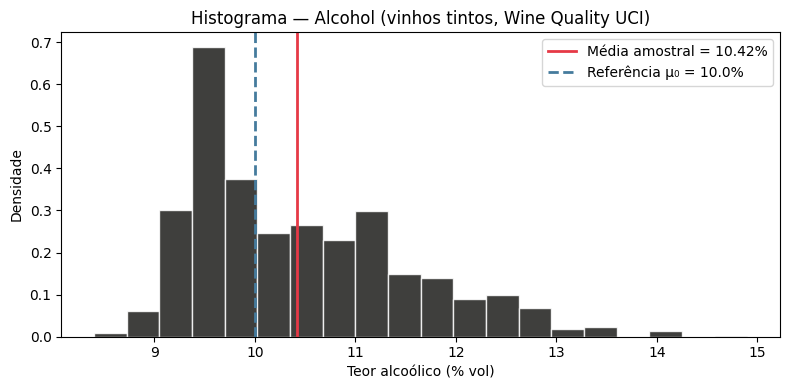

In [2]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["alcohol"], bins=20, color="#1D1D1B", edgecolor="white",
alpha=0.85, density=True)
ax.axvline(xbar, color="#E63946", lw=2, label=f"Média amostral = {xbar:.2f}%")
ax.axvline(mu0,  color="#457B9D", lw=2, ls="--", label=f"Referência μ₀ = {mu0}%")
ax.set_xlabel("Teor alcoólico (% vol)")
ax.set_ylabel("Densidade")
ax.set_title("Histograma — Alcohol (vinhos tintos, Wine Quality UCI)")
ax.legend()
plt.tight_layout(); plt.savefig("hist_alcohol.png", dpi=150)

In [3]:
# Valores críticos bilaterais (α = 0,05)
alpha = 0.05
t_crit = stats.t.ppf(1 - alpha/2, df=n-1)
print(f"t crítico = ±{t_crit:.4f}")
# Valor-p bilateral
p_val = 2 * stats.t.sf(abs(t_obs), df=n-1)
print(f"valor-p = {p_val:.6f}")
# Conferência com ttest_1samp
res = stats.ttest_1samp(df["alcohol"], mu0)
print(res)  # deve coincidir

t crítico = ±1.9614
valor-p = 0.000000
TtestResult(statistic=np.float64(15.871775355324202), pvalue=np.float64(8.61454580988257e-53), df=np.int64(1598))


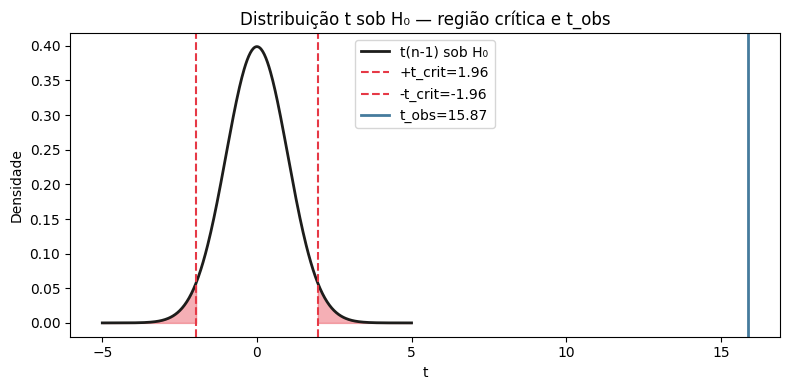

In [7]:
x_vals = np.linspace(-5, 5, 400)
pdf    = stats.t.pdf(x_vals, df=n-1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x_vals, pdf, color="#1D1D1B", lw=2, label="t(n-1) sob H₀")
# Regiões críticas (α = 0,05)
for side, mask in [("left",  x_vals <= -t_crit),("right", x_vals >=  t_crit)]:
    ax.fill_between(x_vals, pdf, where=mask, color="#E63946", alpha=0.4)
ax.axvline( t_crit, color="#E63946", ls="--", lw=1.5, label=f"+t_crit={t_crit:.2f}")
ax.axvline(-t_crit, color="#E63946", ls="--", lw=1.5, label=f"-t_crit={-t_crit:.2f}")
ax.axvline(t_obs,  color="#457B9D", lw=2, label=f"t_obs={t_obs:.2f}")
ax.set_xlabel("t"); ax.set_ylabel("Densidade")
ax.set_title("Distribuição t sob H₀ — região crítica e t_obs")
ax.legend()
plt.tight_layout()
plt.savefig("t_regiao_critica.png", dpi=150)

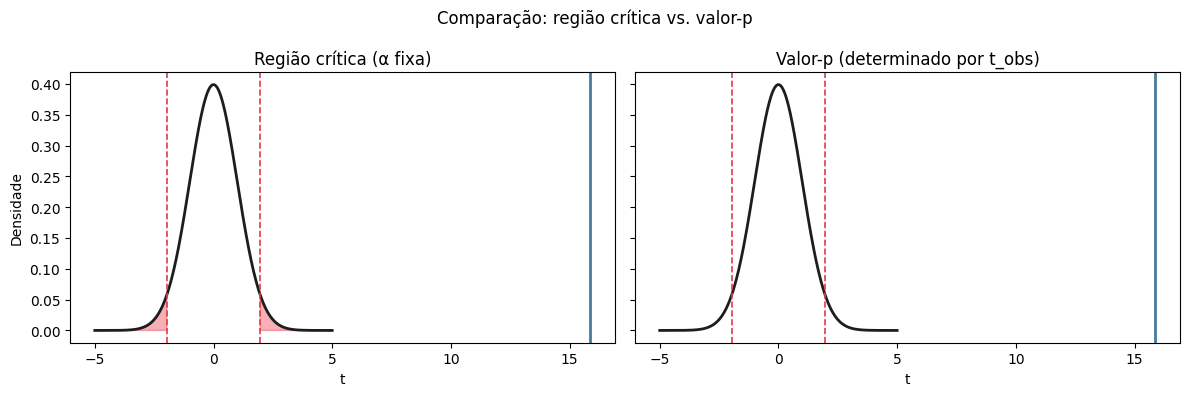

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, title, shade_fn in zip(
    axes,
    ["Região crítica (α fixa)", "Valor-p (determinado por t_obs)"],
    [lambda x: (x <= -t_crit) | (x >= t_crit),
     lambda x: (x <= -abs(t_obs)) | (x >= abs(t_obs))]
):
    ax.plot(x_vals, pdf, color="#1D1D1B", lw=2)
    ax.fill_between(x_vals, pdf, where=shade_fn(x_vals),
                    color="#E63946", alpha=0.4)
    ax.axvline( t_crit, color="#E63946", ls="--", lw=1.2)
    ax.axvline(-t_crit, color="#E63946", ls="--", lw=1.2)
    ax.axvline(t_obs,   color="#457B9D", lw=2)
    ax.set_title(title); ax.set_xlabel("t")
axes[0].set_ylabel("Densidade")
plt.suptitle("Comparação: região crítica vs. valor-p")
plt.tight_layout(); plt.savefig("rc_vs_vp.png", dpi=150)

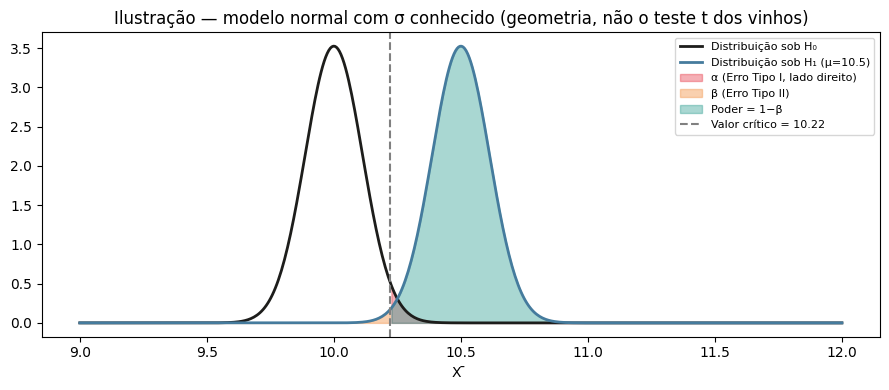

In [9]:
mu1   = 10.5   # alternativa específica (ilustração)
sigma = 0.8    # desvio conhecido (modelo normal — só para ilustrar geometria)
n_il  = 50     # tamanho de amostra hipotético
se_il = sigma / np.sqrt(n_il);z_c   = stats.norm.ppf(1 - 0.05/2)
x_plot = np.linspace(9, 12, 500)
h0_pdf = stats.norm.pdf(x_plot, mu0, se_il)
h1_pdf = stats.norm.pdf(x_plot, mu1, se_il)
lc = mu0 - z_c * se_il   # limite crítico inferior
uc = mu0 + z_c * se_il   # limite crítico superior
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(x_plot, h0_pdf, "#1D1D1B", lw=2, label="Distribuição sob H₀")
ax.plot(x_plot, h1_pdf, "#457B9D", lw=2, label=f"Distribuição sob H₁ (μ={mu1})")
ax.fill_between(x_plot, h0_pdf, where=(x_plot >= uc), color="#E63946",
alpha=0.4, label="α (Erro Tipo I, lado direito)")
ax.fill_between(x_plot, h1_pdf, where=(x_plot <= uc), color="#F4A261",
alpha=0.5, label="β (Erro Tipo II)")
ax.fill_between(x_plot, h1_pdf, where=(x_plot > uc),  color="#2A9D8F",
alpha=0.4, label="Poder = 1−β")
ax.axvline(uc, color="gray", ls="--", lw=1.5, label=f"Valor crítico = {uc:.2f}")
ax.set_xlabel("X ̄ "); ax.legend(fontsize=8)
ax.set_title("Ilustração — modelo normal com σ conhecido (geometria, não o teste t dos vinhos)")
plt.tight_layout(); plt.savefig("poder_erros.png", dpi=150)

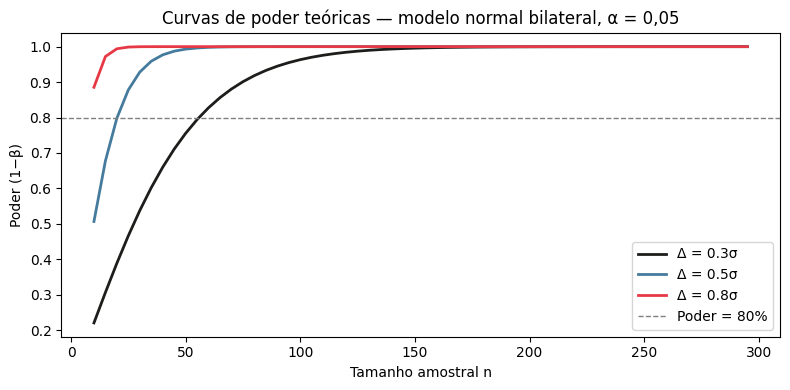

In [10]:
ns     = np.arange(10, 300, 5)
deltas = [0.3, 0.5, 0.8]   # diferenças em unidades de σ
sigma2 = 0.8
fig, ax = plt.subplots(figsize=(8, 4))
colors  = ["#1D1D1B", "#457B9D", "#E63946"]
for delta, col in zip(deltas, colors):
   power = []
   for n_i in ns:
       se_i  = sigma2 / np.sqrt(n_i)
       z_c_i = stats.norm.ppf(0.975)
       uc_i  = mu0 + z_c_i * se_i
       lc_i  = mu0 - z_c_i * se_i
       mu1_i = mu0 + delta
       pw = (stats.norm.sf(uc_i, mu1_i, se_i) +
             stats.norm.cdf(lc_i, mu1_i, se_i))
       power.append(pw)
   ax.plot(ns, power, color=col, lw=2, label=f"Δ = {delta}σ")
ax.axhline(0.80, color="gray", ls="--", lw=1, label="Poder = 80%")
ax.set_xlabel("Tamanho amostral n"); ax.set_ylabel("Poder (1−β)")
ax.set_title("Curvas de poder teóricas — modelo normal bilateral, α = 0,05")
ax.legend(); plt.tight_layout(); plt.savefig("curvas_poder.png", dpi=150)

In [11]:
import pandas as pd, numpy as np
from scipy import stats
import matplotlib.pyplot as plt


n=1599 | x̄=10.4230 | s=1.0657 | EP=0.02665
t_obs=15.8718 | t_crit=±1.9614 | p=0.000000
Conferência scipy: t=15.8718, p=0.000000


In [12]:
# --- 1. Leitura dos dados --
url = ("https://archive.ics.uci.edu/ml/machine-learning-databases"
"/wine-quality/winequality-red.csv");df = pd.read_csv(url, sep=";")


In [13]:
# --- 2. Conferência de ausentes --
assert df["alcohol"].isna().sum() == 0, "Há valores ausentes em 'alcohol'!"

In [14]:
# --- 3. Estatísticas descritivas --
x = df["alcohol"]
n = len(x)
xbar = x.mean()
s = x.std(ddof=1)
se = s / np.sqrt(n)
mu0 = 10.0

In [15]:
# --- 4. Estatística de teste --
t_obs = (xbar - mu0) / se
alpha = 0.05
t_crit = stats.t.ppf(1 - alpha/2, df=n-1)

In [16]:
# --- 5. Valor-p bilateral --
p_val = 2 * stats.t.sf(abs(t_obs), df=n-1)

In [18]:
# --- 6. Conferência com ttest_1samp --
res = stats.ttest_1samp(x, mu0)
print(f"n={n} | x̄={xbar:.4f} | s={s:.4f} | EP={se:.5f}")


n=1599 | x̄=10.4230 | s=1.0657 | EP=0.02665


In [21]:
print(f"t_obs={t_obs:.4f} | t_crit=±{t_crit:.4f} | p={p_val:.6f}")


t_obs=15.8718 | t_crit=±1.9614 | p=0.000000


In [22]:
print(f"Conferência scipy: t={res.statistic:.4f}, p={res.pvalue:.6f}")

Conferência scipy: t=15.8718, p=0.000000
